## **Importacion de librerias necesarias**

In [5]:
import numpy as np

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import time

---

## **Carga y preprocesamiento de las imagenes**

In [6]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False) #importar el dataset

x = (mnist.data / 255.0).reshape(-1, 1, 28 ,28)            # (70000 imagenes de 28x28 pixeles), **normalizado** a [0, 1]
y = mnist.target.astype(int)      # las etiquetas vienen como texto, hay que pasarlas a int

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25,
                                                    random_state=42, stratify=y)  #partición datos para test y train

encoder = OneHotEncoder(sparse_output=False) #one H_outt encoding para las etiquetas
y_train_oh = encoder.fit_transform(y_train.reshape(-1, 1)) #etiquetas entrenamiento   #primero reshape y luego encoder

print(x_train.shape, y_train_oh.shape, x_test.shape, y_test.shape)

(52500, 1, 28, 28) (52500, 10) (17500, 1, 28, 28) (17500,)


---

### **Funciones de activacion del MLP y sus derivadas**

In [7]:
#definir funciones de activacion y derivada

def tanh(x):   #funcion activacion capa oculta
  return np.tanh(x)

def derivada_tanh(x):  #derivada para backpropagation y actualizacion de pesos con gradiente descendente
  return 1 - np.tanh(x)**2

def softmax(x):
  x = x - np.max(x, axis=1, keepdims=True)  #a cada fila le resta su valor maximo lo que evita que e^x de infinito cuando x es muy grande
                                            #conserva las dimensiones [n,1] en lugar de [n,] para poder restar cada fila con su valor  ([nxp]-[nx1])

  return np.exp(x) / np.sum(np.exp(x), axis=1, keepdims=True) #aplica softmax  (suma toda la fila y divide cada numero entre el total (cada numero esta
                                                              #asociado a una clase (columna)))


### **Funcion de perdida**

In [8]:
def cross_entropy(y, y_pred):

  epsilon = 1e-15 #0.000000000000001
  y_pred = np.clip(y_pred, epsilon, 1 - epsilon) #limitamos los extremos
                                                     #para evitar errores de log(0)

  log_loss = -np.mean(np.sum(y * np.log(y_pred), axis=1))  #categorical cross entropy
  return log_loss


---

### **MLP**

-Para la capa densa de la CNN (tomado del notebook en el que lo implemento desde cero y con algunas modificaciones para ajustarlo a la CNN) (el metodo back_propagation, ahora devuelve tres valores en lugar de dos, se le añadio dx, el gradiente respecto a la entrada de la capa densa, es decir, el flatten)

In [9]:
class MLP:
  def __init__(self, input_size, hidden_layers, output_size):

    self.weights = []
    self.biases = []

    #inicializacion de pesos con xavier/glorot initialization
    layer_sizes = [input_size] + hidden_layers + [output_size]    #une en una lista

    for layer in range(len(layer_sizes)-1): #si hay n capas hay n-1 matrices de pesos
      input_dim = layer_sizes[layer]      #obtiene el la cantidad de neuronas de la capa de origen
      output_dim = layer_sizes[layer + 1]  #y de la capa de destino para la conexion actual

      limit = np.sqrt(6 / (input_dim + output_dim))

      W = np.random.uniform(-limit, limit, size=(input_dim, output_dim))  #la columna x contiene los pesos que le entran a la neurona x
      b = np.zeros(output_dim)

      self.weights.append(W)
      self.biases.append(b)


  def feed_forward(self, x):

    netas = []
    activaciones = [x]  #guarda las activaciones de la capa0 (la de entrada), que son los datos de entrada

    for i in range(len(self.weights)):
      neta = activaciones[i] @ self.weights[i] + self.biases[i]
      netas.append(neta)

      if i == len(self.weights)-1:
        activacion = softmax(neta)

      else:
        activacion = tanh(neta)

      activaciones.append(activacion)

    return activacion, netas, activaciones



  def back_propagation(self, y, y_pred, activations, netas):

    m = y.shape[0]  #numero de registros para obtener el gradiente promedio

    dW = [None] * len(self.weights)   #crea una lista llena de None para guardar el gradiente de los pesos
    db = [None] * len(self.biases)

    # Gradiente de la **capa de salida**
    delta = y_pred - y  #error en la capa de salida

    dW[-1] = activations[-2].T @ delta / m   #multiplica la salida de la ultima capa oculta "[-2]" traspuesta por el error delta
    db[-1] = np.sum(delta, axis=0) / m     #el gradiente del bias es el delta (suma los delta de la fila)


    #retroceder por las capas ocultas
    for l in range(len(self.weights) - 2, -1, -1):  #recorre las capas desde la penultima hasta la primera disminuyendo de una en una

        delta = (delta @ self.weights[l + 1].T) * derivada_tanh(netas[l])  #multiplica los delta de la capa siguiente por los pesos de la capa siguiente que son las salidas de
                                                                        #esa capa y los multiplica por dy/dz

        dW[l] = activations[l].T @ delta / m  #calcula el gradiente de la capa l (dz/dw = x) -> por eso usa la activacion (ejemplo: en la acapa 0 la activacion seria
                                              # igual a x)
        db[l] = np.sum(delta, axis=0) / m   #el dz/db es igual a 1


    dx = delta @ self.weights[0].T  #gradiente respecto a la entrada - pesos de la primera capa

    return dW, db, dx #se añade dx para q tambien devuelva el gradiente respecto a la entrada



  def gradiente_descendente(self, dW, db, ln):

      for i in range(len(self.weights)):

        self.weights[i] -= ln * dW[i]
        self.biases[i] -= ln * db[i]



  def fit(self, x, y, epocas, ln):
      #pasar y en one hot
      loss_history = []
      for epoca in range(epocas):
        y_pred, netas, activations = self.feed_forward(x)
        loss = cross_entropy(y, y_pred)
        dW, db = self.back_propagation(y, y_pred, activations, netas)
        self.gradiente_descendente(dW, db, ln)

        loss_history.append(loss)

        #mostrar progreso
        if epoca % 10 == 0:
            print(f"Epoch {epoca}: Loss = {loss:.4f}")

      return loss_history  #devuelve el historial de la perdida durante las epocas del entrenamiento


  def predict(self, x_train):

      y_pred, _, _ = self.feed_forward(x_train)
      return np.argmax(y_pred, axis=1)


  def predict_proba(self, x_train):

      y_pred, _, _ = self.feed_forward(x_train)
      return y_pred



### **Funcion de activacion para la CNN y Max_Pooling con sus derivadas**

In [10]:
def ReLU(feature_map):
  activation_map = np.maximum(0, feature_map)
  return activation_map

def d_relu(da, z):
  return da * (z > 0)


def max_pooling(activation_map, pool_size=2):
  numero_canales, height, width = activation_map.shape
  h_out = height//pool_size
  w_out = width//pool_size

  pooling = np.zeros((numero_canales, h_out, w_out))   #guarda los resultados del max pooling
  mask = np.zeros_like(activation_map, dtype = bool) #inicializada en false (0->false)
                                                     #registra dónde estaban los maximos para utilizarlos durante el backpropagation

  for canal in range(numero_canales):
    for i in range(h_out):
      for j in range(w_out):

        h = i * pool_size  #calcular la posicion inicial de cada ventana
        w = j * pool_size

        region = activation_map[canal, h:h + pool_size, w:w + pool_size]

        #posicion del maximo dentro de la ventana actual
        idx = np.argmax(region)  #devuelve el indice plano del valor maximo de la ventana (recorre por filas de izq a derecha y de arriba a bajo, devuelve un solo numero)
        coord_i, coord_j = np.unravel_index(idx, region.shape) #convierte el indice plano en coordenadas i,j dentro de la ventana



        pooling[canal, i, j] = region[coord_i, coord_j]
        mask[canal, h + coord_i, w + coord_j] = True  #mapea la posicion del maximo en la mask con dimensiones originales de activation_map

  return pooling, mask


def d_pooling(dpool, mask, pool_size=2):
  dpool_expandido = np.repeat(np.repeat(dpool, pool_size, axis=1), pool_size, axis=2)  #expande el gradiente 2 veces por fila y 2 veces por columna
  #ejemplo gradiente 3 -> 3 3
                       #  3 3

  #si el pooling descartó filas/columnas sobrantes, rellenar con ceros hasta el tamaño de la mask
  _, h, w = mask.shape
  _, h_exp, w_exp = dpool_expandido.shape
  dpool_expandido = np.pad(dpool_expandido, ((0, 0), (0, h - h_exp), (0, w - w_exp)))


  return dpool_expandido * mask



## **CNN:**

In [11]:
class CNN:
  def __init__(self, num_filters, filter_size, input_channels, input_size, pool_size, output_size):
    """
    num_filters = numero de filtros (kernels) que tendra la CNN
    filter_size = tamaño del filtro (3x3)
    input_channels = Cantidad de canales de la imagen (1 -> imagen a blanco y negro  -  3 -> Imagen a color RGB)
    input_size = tamaño de la imagen de entrada (28x28)
    pool_size = Tamaño de la ventana del max_pooling
    output_size = Total de etiquetas en las imagenes (MNIST = 10, numeros del 0 al 9)
    """

    #asignacion de parametros a los atributos de la instancia
    self.num_filters = num_filters
    self.filter_size = filter_size
    self.input_channels = input_channels
    self.input_size = input_size
    self.pool_size = pool_size
    self.output_size = output_size

    #inicializacion parametros (pesos) de la capa convolucional (inicializacion "He", por usar ReLU)
    params_per_filter = filter_size**2 * input_channels   #calcula cuantos pesos tiene cada kernel
    self.weights= np.random.randn(num_filters, input_channels, filter_size, filter_size) * np.sqrt(2/params_per_filter)
    #.randn genera numeros con dist normal estandar (media 0 var 1) pero como necesitamos que tengan una varianza especifica los multiplicamos
    #por la varianza de "He" para obtener pesos con varianza 2 / params_per_filter
    #crea un tensor de pesos con forma: [num_filter, input_channels, filter_size, filter_size]
    self.bias = np.zeros(num_filters) #un bias por cada kernel

    #calcular el tamaño de salida de la convolucion y el tamaño de salida del pooling para calcular el tamaño del flatten
    conv_out = (input_size - filter_size) + 1  #asumiendo padding 0 y stride 1
    pooling_out = conv_out // pool_size  #si es un numero impar por ejemplo 27//2 da 13 y se descarta la ultima columna, eso se arregla en el d_pooling
                                         #rellenando con ceros hasta el tamaño de mask
    flatten_size = pooling_out**2 * num_filters

    #instanciar el MLP
    self.mlp = MLP(input_size=flatten_size, hidden_layers=[], output_size=output_size) #sin capas ocultas



  def conv2d(self, x):
    """
    x: entrada (imagen) - (canales, height, width)

    devuelve:
        feature_map: (num_filtros, H_out, W_out) - resultado de la convolucion antes de activacion
    """
    padding=0
    stride=1

    num_filtros, canales_por_filtro, height_f, width_f = self.weights.shape
    _, height_i, width_i = x.shape

    h_out = (height_i - height_f + 2*padding)//stride + 1  #height de salida luego de la convolucion
    w_out = (width_i - width_f + 2*padding)//stride + 1    #width de salida luego de la convolucion

    feature_map = np.zeros((num_filtros, h_out, w_out))

    for f in range(num_filtros):  #itera en cada kernel
        for i in range(h_out):  #itera en el height
            for j in range(w_out):    #itera en el width
                region = x[:, i:i + height_f, j:j + width_f] #todos los canales de entrada
                                                            #selecciona un region de la imagen del tamaño del filtro. De forma (canales, height_f, width_f)

                feature_map[f, i, j] = (np.sum(region * self.weights[f]) + self.bias[f])  #calcula la convolucion y la guarda en el canal y la posicion
                                                                                          #de la iteracion

    return feature_map


  def d_conv2d(self, dz, x): #recibe los gradientes de z (de/dz) y la imagen que entro a la conv
    """
    dz: gradiente respecto a la salida de la conv (F, H_out, W_out) -> cuanto cambia la perdida si cambia la neta (delta)
    x:  entrada que tuvo la conv en el forward (C, H, W)

    devuelve:
        dw: gradiente de los pesos de los filtros  (F, C, hf, wf)
        db: gradiente de los sesgos   (F,)
        dx: gradiente de la entrada   (C, H, W)  (por ahora no se usa ya que solo hay 1 capa conv y no hay otra a la que pasarle el error)
    """
    F, C, hf, wf = self.weights.shape
    _, h_out, w_out = dz.shape

    dw = np.zeros_like(self.weights) #empiezan en 0 para ir acumulando los gradientes
    db = np.zeros_like(self.bias)
    dx = np.zeros_like(x)

    for f in range(F): #itera sobre los kernel
      db[f] = np.sum(dz[f])  #dE/db = dE/dz · dz/db. Como z = suma(region * w) + b, el sesgo se suma solo (nada lo multiplica), así que dz/db = 1 y cada
            #posición aporta su dz tal cual. El mismo b se usó en todas las posiciones del filtro, por eso su gradiente es la suma de todos los dz de ese filtro.

      for i in range(h_out):
        for j in range(w_out):
          region = x[:, i:i + hf, j:j + wf]  #la misma ventana que uso el forward

          dw[f] += region * dz[f, i, j]   #(de/dw = de/dz · dz/dw) el filtro multiplico a los pixeles dentro de la region asi que es la suma del gradiente en todas
                                          #las regiones (Se acumula (+=) porque el mismo filtro se usó en todas las posiciones) en las que se aplico el filtro.
                                          #Si ese peso sube en 1, z sube en el valor de ese pixel.

          dx[:, i:i + hf, j:j + wf] += self.weights[f] * dz[f, i, j]   #Si un píxel sube en 1, z sube en el valor de su peso
                                                                      #se usaria si hubiesen mas capas de conv para pasar el error a la anterior

    #dw -> (8, 1, 3, 3) (un gradiente por cada peso)  db -> (8,)  dx -> (1, 28, 28)
    return dw, db, dx  #devuelve la sumatoria de los gradientes en cada ventana por la que pasó el kernel y el gradiente de la entrada


  def feed_forward(self, x):  #recorrido completo hacia adelante
    """
    x: una imagen (canales, alto, ancho)
    devuelve: probabilidades (1 imagen de entrada, 10 probabilidades) y un cache con lo necesario para el backward
    """

    z = self.conv2d(x)  # (F, 26, 26)  aplica la convolucion y devuelve el featuremap de la imagen
    a = ReLU(z)         # (F, 26, 26) aplica la funcion de activacion y devuelve el activationmap
    pool, mask = max_pooling(a, self.pool_size)  # (F, 13, 13) aplica el maxpooling

    flat = pool.reshape(1, -1)  # (1, 1352) aplica el flatten para pasar aplanado al MLP

    probs, netas, activaciones = self.mlp.feed_forward(flat)   # (1, 10) retorna las probabilidades de pertenecer a cada clase, las netas y las activaciones

    cache = {
        "x": x,    #guarda el x (la imagen) para calcular en d_conv2d el dw
        "z": z,    #guarda la neta de la convolucion (el feature map) lo usa d_relu para saber dónde z > 0
        "mask": mask,  #guarda la mascara. #True en la posición del máximo de cada ventana del pooling; d_pooling la usa para repartir el gradiente solo ahi
        "pool_shape": pool.shape,   #se usa para deshacer el flatten en el backpropagation
        "netas": netas,  #se usan para el backpropagation del mlp
        "activaciones": activaciones} #se usan para el backpropagation del mlp

    #retorna probs para calcular la perdida y la prediccion y el cache para los calculos del backpropagation
    return probs, cache


  def backpropagation_cnn(self, y, probs, cache):
    #gradientes capa densa y el gradiente que llega al flatten
    dw_mlp, db_mlp, dx_flatten = self.mlp.back_propagation(y, probs, cache["activaciones"], cache["netas"])

    #deshacer el flatten  (1, 1352) -> (8, 13, 13)
    dpool = dx_flatten.reshape(cache["pool_shape"])

    #deshacer pooling y ReLU
    da = d_pooling(dpool, cache["mask"], self.pool_size)  #da (de/da) es el gradiente de la perdida respecto a la salida de relu (activation map).
                                                          #solo es distinto de 0 donde estaba el máximo (mask)
    dz = d_relu(da, cache["z"])

    #gradientes de la convolucion
    dw_conv, db_conv, _ = self.d_conv2d(dz, cache["x"])

    return dw_conv, db_conv, dw_mlp, db_mlp



  def gradiente_descendente(self, dw_conv, db_conv, dw_mlp, db_mlp, ln): #le entran los gradientes de los pesos y bias para actualizarlos
    self.weights -= ln * dw_conv
    self.bias -= ln * db_conv
    self.mlp.gradiente_descendente(dw_mlp, db_mlp, ln) #llama al metodo de gradiente descendente del mlp para actualizar los pesos y bias del mlp


  def fit(self, x, y, epocas, ln, batch_size=32):
    n = x.shape[0] #total muestras
    loss_history = []  #guardar el historial de la perdidad

    for epoca in range(epocas): #itera sobre las epocas
      idx = np.random.permutation(n)  #mezcla los indices para cambiar el orden de los lotes en cada epoca
      loss_epoca = 0  #acumulador de la perdida generada por cada imagen

      for start in range(0, n, batch_size):  #itera sobre las muestras dando pasos de tamaño batch_size
        batch = idx[start:start + batch_size]  #va cambiando las muestras del batch que toma
        m = len(batch)   #para dividir por el tamaño real del lote en caso de que el ultimo sea mas pequeño

        #acumuladores, uno por cada parametro, se reinician en cada batch
        acc_dw_conv = np.zeros_like(self.weights)
        acc_db_conv = np.zeros_like(self.bias)
        acc_dw_mlp = [np.zeros_like(w) for w in self.mlp.weights] #el MLP se hace con listas porque self.mlp.weights es una lista de matrices (una por capa).
        acc_db_mlp = [np.zeros_like(b) for b in self.mlp.biases]

        for k in batch: #para cada imagen en el batch
          probs, cache = self.feed_forward(x[k])   #hace el feed_forward sobre la imagen
          yk = y[k:k+1]   #obtiene la eiqueta one hot de tamaño (1, 10) con slicing para dejarlo como arreglo 2d
          loss_epoca += cross_entropy(yk, probs) #calcula la perdida y la añade a la perdida de la epoca

          dwc, dbc, dwm, dbm = self.backpropagation_cnn(yk, probs, cache) #obtiene los gradientes del backpropagation
          acc_dw_conv += dwc  #suma el gradiente de esta imagen al acumulador del lote
          acc_db_conv += dbc
          for l in range(len(acc_dw_mlp)): #la parte del MLP se suma con un bucle porque son listas
            acc_dw_mlp[l] += dwm[l]
            acc_db_mlp[l] += dbm[l]

        self.gradiente_descendente(
            acc_dw_conv / m, acc_db_conv / m,
            [g / m for g in acc_dw_mlp], [g / m for g in acc_db_mlp], ln) #le pasa los gradientes promedio al metodo de gradiente descendente para que haga
                                                                          #la actualizacion (ya divididos por la cantidad de muestras del batch - promedio gradiente)

      loss_history.append(loss_epoca / n)  #añade al historial la perdida de la epoca
      print(f"Epoca {epoca}: Loss = {loss_epoca / n:.4f}")

    return loss_history


  def predict(self, x):
    """hace el feed forward de las imagenes que se quiere predecir y obtiene las probabilidades, luego selecciona el indice con el valor mas grande
       y lo devuelve como prediccion del numero ya que la posición k corresponde al dígito k. El [0] solo toma las probs (ya que el forward devuelve probs y cache)
    """
    return np.array([np.argmax(self.feed_forward(img)[0]) for img in x])




---

## **Entrenar la CNN**

In [117]:
cnn = CNN(num_filters=8, filter_size=3, input_channels=1,
          input_size=28, pool_size=2, output_size=10)

n_prueba = 15000 #limitamos los datos de entrenamiento debido al tiempo (aprox 0.1 segundos por imagen)
t0 = time.time()
hist = cnn.fit(x_train[:n_prueba], y_train_oh[:n_prueba], epocas=10, ln=0.05, batch_size=32)
print("tiempo:", time.time() - t0)

y_pred = cnn.predict(x_test[:100])
print("Accuracy:", np.mean(y_pred == y_test[:100]))

Epoca 0: Loss = 0.4981
Epoca 1: Loss = 0.3186
Epoca 2: Loss = 0.2685
Epoca 3: Loss = 0.2307
Epoca 4: Loss = 0.1932
Epoca 5: Loss = 0.1639
Epoca 6: Loss = 0.1408
Epoca 7: Loss = 0.1234
Epoca 8: Loss = 0.1099
Epoca 9: Loss = 0.0990
tiempo: 15462.524086475372
Accuracy: 0.99


### **Evaluar el accuracy en train y test**

In [121]:
acc_train = np.mean(cnn.predict(x_train[:15000]) == y_train[:15000])
acc_test  = np.mean(cnn.predict(x_test[:15000])  == y_test[:15000])
print("train:", acc_train, "| test:", acc_test)

train: 0.9762 | test: 0.9594666666666667


Accuracy: 0.9594666666666667


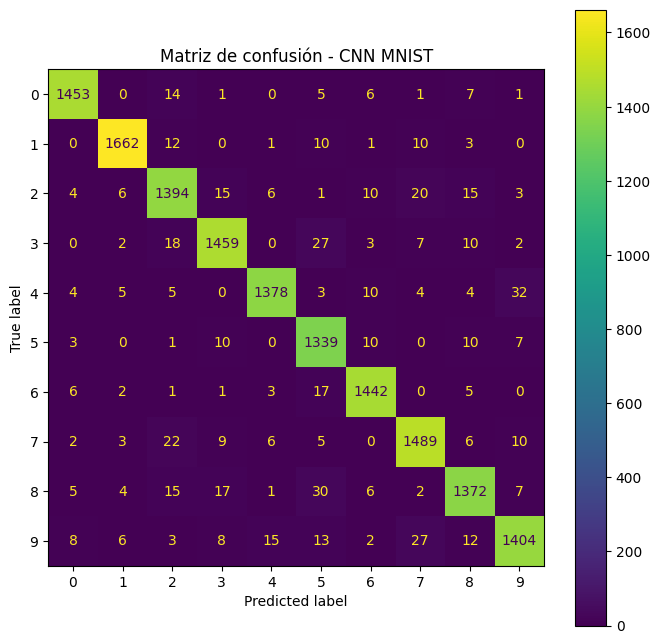

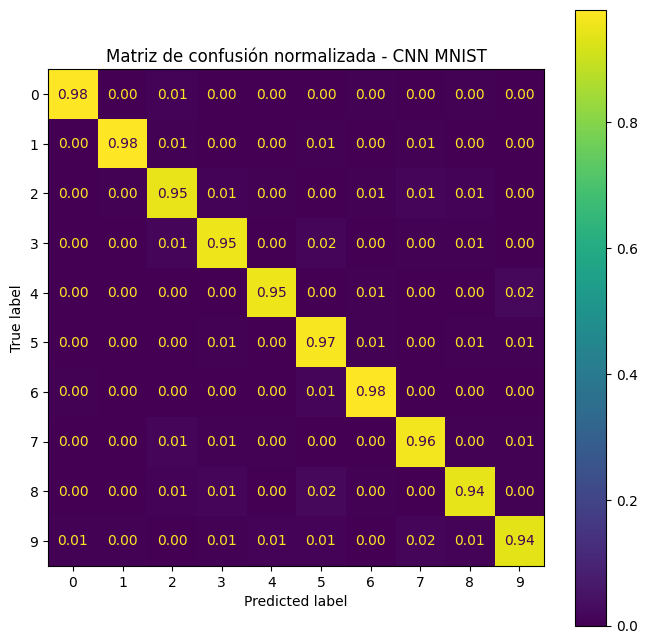

In [145]:
n_eval = 15000
y_pred = cnn.predict(x_test[:n_eval])
y_real = y_test[:n_eval]

print("Accuracy:", np.mean(y_pred == y_real))

#matriz con conteos
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_real, y_pred,
    display_labels=range(10),
    cmap="viridis",
    ax=ax)
plt.title("Matriz de confusión - CNN MNIST")
plt.show()

#matriz normalizada por fila (porcentaje de cada dígito real)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_real, y_pred,
    display_labels=range(10),
    normalize="true",
    values_format=".2f",
    cmap="viridis",
    ax=ax)
plt.title("Matriz de confusión normalizada - CNN MNIST")
plt.show()

## **Guardar los pesos del modelo para evitar reentrenar**

In [130]:
np.savez("cnn_pesos.npz", cnn_w=cnn.weights, cnn_b=cnn.bias, mlp_w=cnn.mlp.weights[0],
         mlp_b=cnn.mlp.biases[0],  loss=np.array(hist))

**Cargar pesos del modelo desde el archivo.npz**

In [12]:
cnn = CNN(num_filters=8, filter_size=3, input_channels=1,
          input_size=28, pool_size=2, output_size=10) #mismos valores que al entrenar

#carga los datos
datos = np.load("cnn_pesos.npz")
cnn.weights = datos["cnn_w"]
cnn.bias = datos["cnn_b"]
cnn.mlp.weights[0] = datos["mlp_w"]
cnn.mlp.biases[0] = datos["mlp_b"]
hist = datos["loss"].tolist()
#predice con lo entrenado (sin volver a entrenar)

---

## **Grafico de la evolucion de la perdida en el entrenamiento**

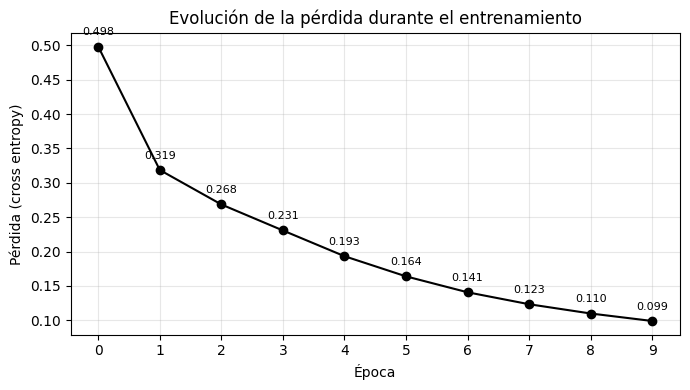

In [13]:
epocas = range(len(hist))

plt.figure(figsize=(7, 4))
plt.plot(epocas, hist, marker="o", color="black")

for e, l in zip(epocas, hist):                    # valor de la pérdida sobre cada punto
    plt.annotate(f"{l:.3f}", (e, l), textcoords="offset points",
                 xytext=(0, 8), ha="center", fontsize=8)

plt.xlabel("Época")
plt.ylabel("Pérdida (cross entropy)")
plt.title("Evolución de la pérdida durante el entrenamiento")
plt.xticks(epocas)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---

## **Grafico de los filtros, mapas de caracteristicas, mapas de activacion y el vector flatten**

In [148]:
x_train[0].shape

(1, 28, 28)

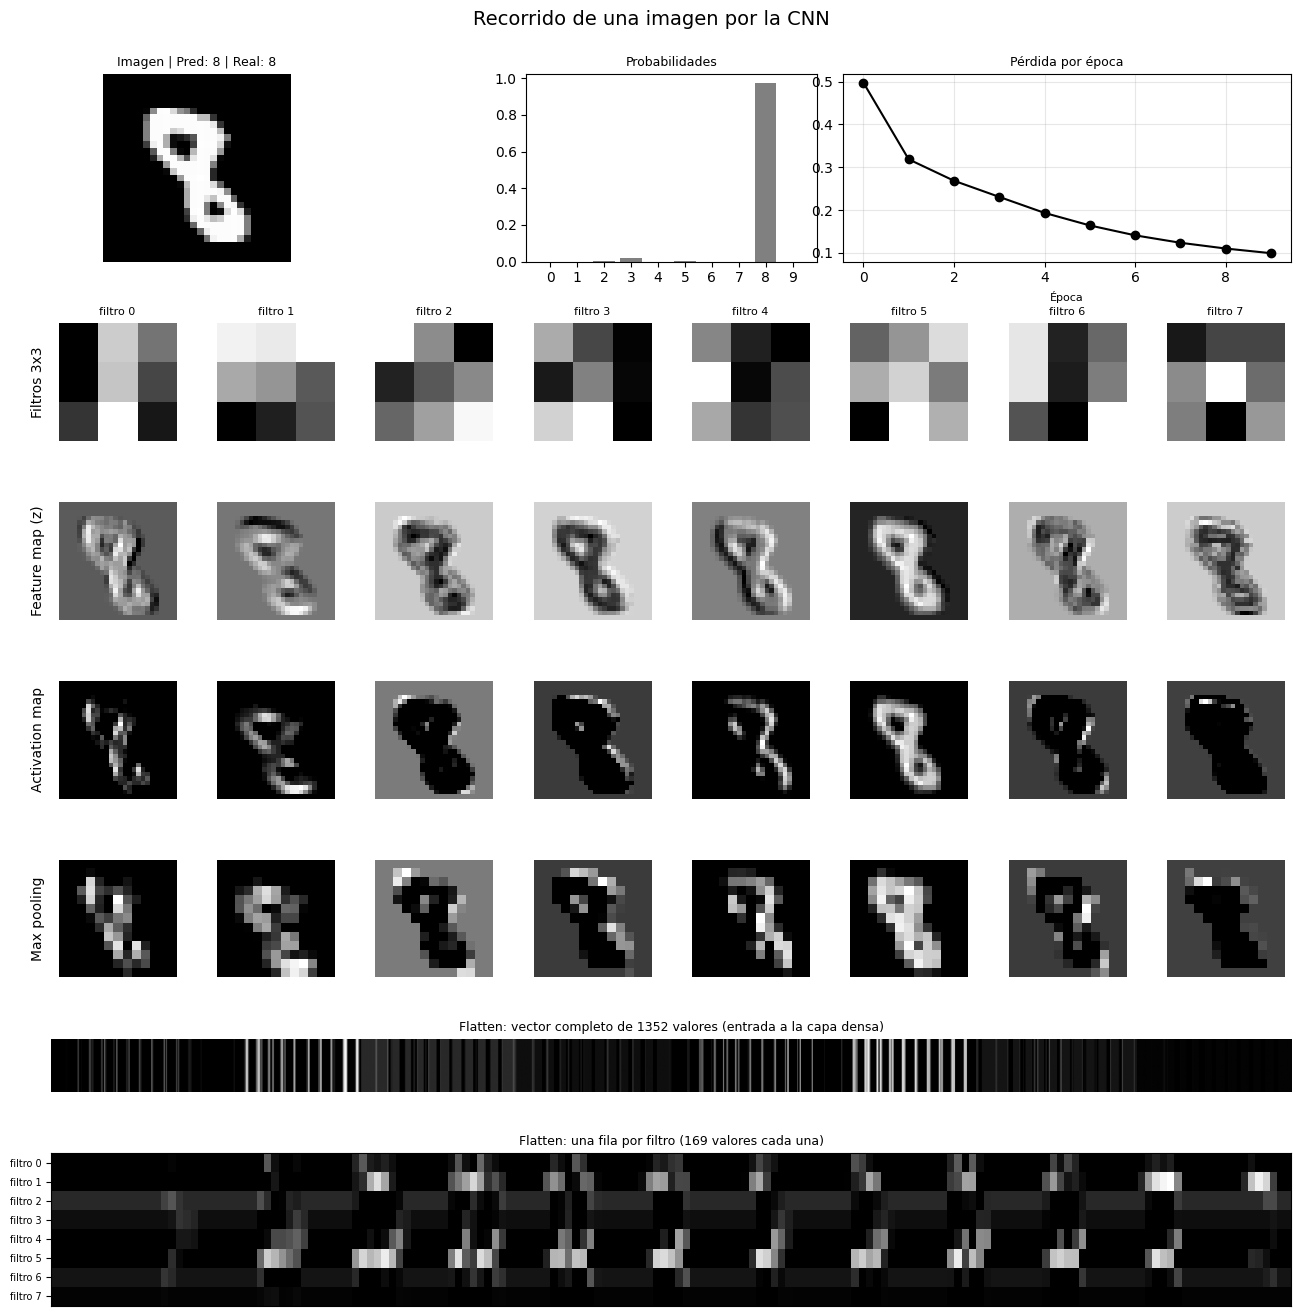

In [52]:
img = x_test[23]
probs, cache = cnn.feed_forward(img)

z = cache["z"]                                   # feature map
a = ReLU(z)                                      # activation map
pool, _ = max_pooling(a, cnn.pool_size)          # tras el pooling
flat_completo = pool.reshape(1, -1)              # (1, 1352): el vector completo que entra a la capa densa
flat = pool.reshape(cnn.num_filters, -1)         # (8, 169): el mismo vector, una fila por filtro

F = cnn.num_filters
fig = plt.figure(figsize=(2 * F, 16))
gs = fig.add_gridspec(7, F, height_ratios=[1.6, 1, 1, 1, 1, 0.45, 1.3], hspace=0.5)

def etiqueta_fila(ax, texto):
    ax.text(-0.18, 0.5, texto, transform=ax.transAxes, rotation=90,
            va="center", ha="center", fontsize=10)

#fila 0: imagen original, probabilidades y perdida
ax = fig.add_subplot(gs[0, 0:2])
ax.imshow(img[0], cmap="gray")
ax.set_title(f"Imagen | Pred: {np.argmax(probs)} | Real: {y_test[23]}", fontsize=9)
ax.axis("off")

ax = fig.add_subplot(gs[0, 3:5])
ax.bar(range(10), probs[0], color="gray")
ax.set_xticks(range(10))
ax.set_title("Probabilidades", fontsize=9)

ax = fig.add_subplot(gs[0, 5:8])
ax.plot(range(len(hist)), hist, marker="o", color="black")
ax.set_title("Pérdida por época", fontsize=9)
ax.set_xlabel("Época", fontsize=8)
ax.grid(alpha=0.3)

#filas 1 a 4: un mapa por filtro
filas = [(cnn.weights[:, 0], "Filtros 3x3"),
         (z, "Feature map (z)"),
         (a, "Activation map"),
         (pool, "Max pooling")]

for r, (mapas, nombre) in enumerate(filas, start=1):
    for f in range(F):
        ax = fig.add_subplot(gs[r, f])
        ax.imshow(mapas[f], cmap="gray")
        ax.axis("off")
        if r == 1:
            ax.set_title(f"filtro {f}", fontsize=8)
        if f == 0:
            etiqueta_fila(ax, nombre)

#fila 5: flatten, vector completo (1352 valores en una sola franja)
ax = fig.add_subplot(gs[5, :])
ax.imshow(flat_completo, cmap="gray", aspect="auto")
ax.set_title("Flatten: vector completo de 1352 valores (entrada a la capa densa)", fontsize=9)
ax.axis("off")

#fila 6: flatten, el mismo vector con una fila por filtro
ax = fig.add_subplot(gs[6, :])
ax.imshow(flat, cmap="gray", aspect="auto")
ax.set_title("Flatten: una fila por filtro (169 valores cada una)", fontsize=9)
ax.set_yticks(range(F))
ax.set_yticklabels([f"filtro {f}" for f in range(F)], fontsize=7)
ax.set_xticks([])

fig.suptitle("Recorrido de una imagen por la CNN", fontsize=14, y=0.92)

plt.savefig("cnn_resumen.png", dpi=200, bbox_inches="tight")
plt.show()